# 04. 하이퍼파라미터 튜닝

**질문: 2일차에 고른 LightGBM 설정(`num_leaves=31`, `n_estimators=500`, `learning_rate=0.05`)을 튜닝하면 더 좋아지나?**

2일차에는 대표값 몇 개만 비교하고 촘촘한 튜닝은 하지 않았다.
검증 기간(2017-01~04) **하나**에 맞춰 수십 번 고르면, 그 4개월에만 잘 맞는 설정을 고르게 되기 때문이다.

이 노트북은 그 문제를 피해서 튜닝한다.
1. **시간 순서 교차검증(3폴드)**: 검증 기간을 하나가 아니라 셋으로 늘린다. 세 기간 모두에서 좋은 설정만 살아남는다.
2. **Optuna(TPE)**로 60회 탐색. 테스트 기간(2017-05~08)은 탐색에 쓰지 않는다.
3. **채택 기준을 탐색 전에 정한다** (아래 3장). 기준을 못 넘으면 기존 설정을 유지한다.
4. 마지막에 테스트 기간에서 **1회만** 기존 설정과 비교한다.

In [1]:
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from lightgbm import LGBMClassifier

from src.data import load_data, final_features, split_xy, time_split, arrival_date
from src.model import make_model, evaluate, compare

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", 50)
optuna.logging.set_verbosity(optuna.logging.WARNING)
SEED = 42
print(sys.executable)
print("optuna", optuna.__version__)

C:\workspace\2026project\project-new-notyet\.venv\Scripts\python.exe
optuna 5.0.0


## 1. 데이터와 기간 나누기

- 피처는 2일차에 확정한 `final_features()` 그대로 (32개).
- 테스트 기간(2017-05~08)은 2일차와 같다. **튜닝 중에는 손대지 않는다.**
- 튜닝용 개발 기간(~2017-04)을 4개월 단위로 잘라 **확장 창(expanding window)** 교차검증을 만든다.
  테스트 기간도 4개월이므로 검증 구간 길이를 맞췄다.

| 폴드 | 학습 | 검증 |
|---|---|---|
| 1 | 2015-07 ~ 2016-04 | 2016-05 ~ 08 (여름 성수기) |
| 2 | 2015-07 ~ 2016-08 | 2016-09 ~ 12 |
| 3 | 2015-07 ~ 2016-12 | 2017-01 ~ 04 (= 2일차 검증 기간) |

- 무작위 K-Fold를 쓰지 않는 이유: 미래 예약으로 학습해 과거를 맞히게 되고, 똑같은 행(단체 예약 묶음)이 학습·검증에 나뉜다.
  도착일로 자르면 같은 묶음은 같은 날짜라 한 구간에만 들어간다.

In [2]:
df = load_data()
X, y = split_xy(final_features(df))
arrival = arrival_date(df)

parts = time_split(df, ["2016-05-01", "2016-09-01", "2017-01-01", "2017-05-01"])
test_idx = parts[-1]
dev_idx = pd.Index([]).append(parts[:-1])   # 테스트 이전 전체 (최종 학습용)

folds = []
for k in range(1, 4):   # 검증 구간 = parts[1], parts[2], parts[3]
    train = pd.Index([]).append(parts[:k])
    folds.append((train, parts[k]))

def period(idx):
    d = arrival.loc[idx]
    return f"{d.min():%Y-%m} ~ {d.max():%Y-%m}"

pd.DataFrame({
    "학습 기간": [period(tr) for tr, _ in folds] + [period(dev_idx)],
    "학습 행 수": [len(tr) for tr, _ in folds] + [len(dev_idx)],
    "평가 기간": [period(va) for _, va in folds] + [period(test_idx)],
    "평가 행 수": [len(va) for _, va in folds] + [len(test_idx)],
    "평가 취소율": [y[va].mean() for _, va in folds] + [y[test_idx].mean()],
}, index=["폴드 1", "폴드 2", "폴드 3", "테스트 (마지막 1회)"]).round(3)

,학습 기간,학습 행 수,평가 기간,평가 행 수,평가 취소율
폴드 1,2015-07 ~ 2016-04,38387,2016-05 ~ 2016-08,20405,0.359
폴드 2,2015-07 ~ 2016-08,58792,2016-09 ~ 2016-12,19911,0.380
폴드 3,2015-07 ~ 2016-12,78703,2017-01 ~ 2017-04,18489,0.365
테스트 (마지막 1회),2015-07 ~ 2017-04,97192,2017-05 ~ 2017-08,22198,0.405


## 2. 기준점: 2일차 설정의 폴드별 점수

튜닝 결과를 비교할 기준. 같은 폴드에서 점수를 재야 비교가 공정하다.

In [3]:
BASE_PARAMS = dict(n_estimators=500, learning_rate=0.05, num_leaves=31)

def lgbm(**params):
    return LGBMClassifier(verbose=-1, random_state=SEED, **params)

def cv_scores(params):
    """폴드별 검증 ROC-AUC·PR-AUC."""
    rows = []
    for tr, va in folds:
        model = make_model(X, lgbm(**params), tree=True).fit(X.loc[tr], y.loc[tr])
        s = evaluate(model, X.loc[va], y.loc[va])
        rows.append({"roc_auc": s["roc_auc"], "pr_auc": s["pr_auc"]})
    return pd.DataFrame(rows, index=["폴드 1", "폴드 2", "폴드 3"])

t = time.perf_counter()
base_cv = cv_scores(BASE_PARAMS)
print(f"3폴드 학습·평가 {time.perf_counter() - t:.1f}초")
base_cv.loc["평균"] = base_cv.mean()
base_cv.round(4)

3폴드 학습·평가 6.3초


,roc_auc,pr_auc
폴드 1,0.8724,0.8297
폴드 2,0.8580,0.8219
폴드 3,0.9011,0.8564
평균,0.8771,0.8360


- 폴드 3(2017-01~04)의 0.901은 2일차 검증 점수와 같다 → 같은 설정을 제대로 재현했다.
- **폴드끼리 점수 차이가 0.04 이상 난다.** 모델이 아니라 기간에 따라 맞히기 쉬운 정도가 다르다는 뜻이다.
  그래서 튜닝 전후는 같은 폴드끼리(짝지어) 비교한다.

## 3. 채택 기준 (탐색 전에 고정)

튜닝한 설정은 아래 두 조건을 **모두** 만족할 때만 채택한다. 아니면 기존 설정을 유지한다.
1. 3폴드 평균 ROC-AUC가 기준점보다 **+0.003 이상** 높다.
2. **3개 폴드 모두**에서 기준점보다 높다 (특정 기간에서만 좋은 설정 배제).

- +0.003은 2일차에 "잡음 수준"으로 본 차이(subsample +0.0007, CatBoost +0.001)보다 확실히 큰 값이다.
- 60번 시도 중 최고를 고르면 그 자체로 점수가 조금 부풀려진다. 그래서 문턱을 0보다 높게 둔다.

## 4. Optuna 탐색

**탐색 범위** — 트리 복잡도, 학습 속도, 규제 세 축

| 파라미터 | 범위 | 역할 |
|---|---|---|
| `learning_rate` | 0.01 ~ 0.2 (로그) | 트리 하나가 얼마나 크게 고치나 |
| `n_estimators` | 200 ~ 1500 | 트리 수. 학습률과 짝 (작은 학습률 = 많은 트리) |
| `num_leaves` | 8 ~ 128 | 트리 하나의 복잡도 |
| `min_child_samples` | 10 ~ 300 (로그) | 잎 하나의 최소 예약 수. 클수록 특정 예약 묶음을 덜 외움 |
| `subsample` | 0.5 ~ 1.0 | 트리마다 쓰는 행 비율 |
| `colsample_bytree` | 0.4 ~ 1.0 | 트리마다 쓰는 열 비율. `deposit_type`·`country` 의존을 줄일 수 있음 |
| `reg_lambda` | 0.001 ~ 10 (로그) | L2 규제 |

- 목적 함수: 3폴드 평균 ROC-AUC (주 지표).
- TPE 샘플러: 앞선 시도 결과를 보고 좋은 영역을 더 많이 탐색. `seed=42`로 재현 가능.
- 첫 시도는 기존 설정(`enqueue_trial`)으로 해서 탐색 결과를 같은 기준에서 비교한다.

In [4]:
def suggest(trial):
    return dict(
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        n_estimators=trial.suggest_int("n_estimators", 200, 1500, step=50),
        num_leaves=trial.suggest_int("num_leaves", 8, 128, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 10, 300, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        subsample_freq=1,
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    )

def objective(trial):
    scores = cv_scores(suggest(trial))
    for i, v in enumerate(scores["roc_auc"]):   # 폴드별 점수도 기록해 둔다
        trial.set_user_attr(f"fold{i + 1}", v)
    trial.set_user_attr("pr_auc", scores["pr_auc"].mean())
    return scores["roc_auc"].mean()

N_TRIALS = 60
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
# 기존 설정을 첫 시도로 (subsample=1, colsample=1, 기본 min_child_samples=20, reg_lambda≈0)
study.enqueue_trial(dict(learning_rate=0.05, n_estimators=500, num_leaves=31, min_child_samples=20,
                         subsample=1.0, colsample_bytree=1.0, reg_lambda=1e-3))

t = time.perf_counter()
study.optimize(objective, n_trials=N_TRIALS)
print(f"{N_TRIALS}회 탐색 {(time.perf_counter() - t) / 60:.1f}분")
print(f"최고 3폴드 평균 ROC-AUC: {study.best_value:.4f} (시도 #{study.best_trial.number})")

60회 탐색 6.4분
최고 3폴드 평균 ROC-AUC: 0.8933 (시도 #47)


In [5]:
trials = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs"))
trials.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in trials.columns]
trials = trials.rename(columns={"value": "roc_auc_mean"})
cols = ["number", "roc_auc_mean", "fold1", "fold2", "fold3", "pr_auc",
        "learning_rate", "n_estimators", "num_leaves", "min_child_samples",
        "subsample", "colsample_bytree", "reg_lambda"]
trials[cols].sort_values("roc_auc_mean", ascending=False).head(10).round(4)

,number,roc_auc_mean,fold1,fold2,fold3,pr_auc,learning_rate,n_estimators,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda
47,47,0.8933,0.8901,0.8894,0.9003,0.8536,0.0149,850,8,80,0.8560,0.8284,2.4503
43,43,0.8931,0.8897,0.8851,0.9046,0.8531,0.0190,1100,9,82,0.8351,0.6749,1.6981
55,55,0.8927,0.8900,0.8869,0.9012,0.8531,0.0142,1050,8,57,0.8700,0.7832,1.2307
46,46,0.8926,0.8882,0.8869,0.9026,0.8533,0.0168,1000,9,55,0.8065,0.8341,8.1796
59,59,0.8924,0.8892,0.8864,0.9014,0.8529,0.0122,1100,8,53,0.8524,0.7300,3.1950
33,33,0.8924,0.8883,0.8864,0.9023,0.8531,0.0131,950,9,75,0.7482,0.8378,1.6294
48,48,0.8923,0.8891,0.8852,0.9028,0.8528,0.0158,1200,9,50,0.8392,0.8092,2.7784
23,23,0.8923,0.8880,0.8854,0.9035,0.8529,0.0181,900,10,76,0.8196,0.7912,3.4997
45,45,0.8923,0.8896,0.8845,0.9027,0.8526,0.0171,850,9,82,0.8056,0.7104,1.1545
41,41,0.8922,0.8886,0.8837,0.9043,0.8524,0.0202,1100,9,90,0.7795,0.7588,3.2966


### 4-1. 탐색 과정과 파라미터 중요도
- 왼쪽: 시도가 쌓일수록 최고 점수가 어떻게 올라갔나. 빨간 점선이 기존 설정(시도 #0).
- 오른쪽: 어떤 파라미터가 점수를 좌우했나 (fANOVA — 점수 변동을 파라미터별로 나눔).

num_leaves           0.693
subsample            0.131
n_estimators         0.042
reg_lambda           0.036
colsample_bytree     0.036
min_child_samples    0.032
learning_rate        0.032
dtype: float64

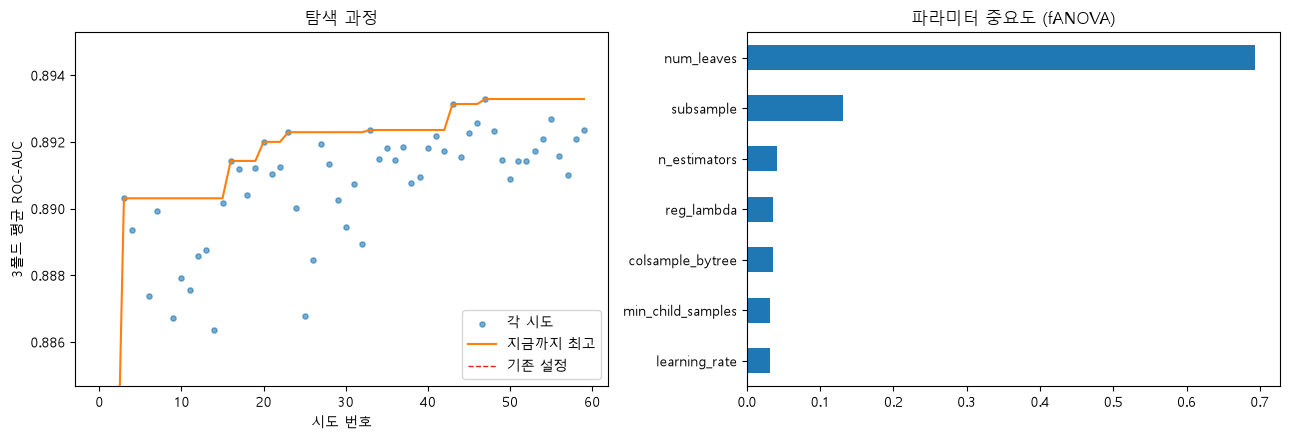

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.scatter(trials["number"], trials["roc_auc_mean"], s=14, alpha=0.6, label="각 시도")
ax.plot(trials["number"], trials["roc_auc_mean"].cummax(), color="C1", label="지금까지 최고")
ax.axhline(trials.loc[0, "roc_auc_mean"], color="C3", ls="--", lw=1, label="기존 설정")
ax.set_ylim(trials["roc_auc_mean"].quantile(0.1) - 0.002, trials["roc_auc_mean"].max() + 0.002)
ax.set_xlabel("시도 번호"); ax.set_ylabel("3폴드 평균 ROC-AUC"); ax.set_title("탐색 과정")
ax.legend(loc="lower right")

imp = pd.Series(optuna.importance.get_param_importances(
    study, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED))).sort_values()
imp.plot.barh(ax=axes[1], color="C0")
axes[1].set_title("파라미터 중요도 (fANOVA)")
plt.tight_layout()
imp.sort_values(ascending=False).round(3)

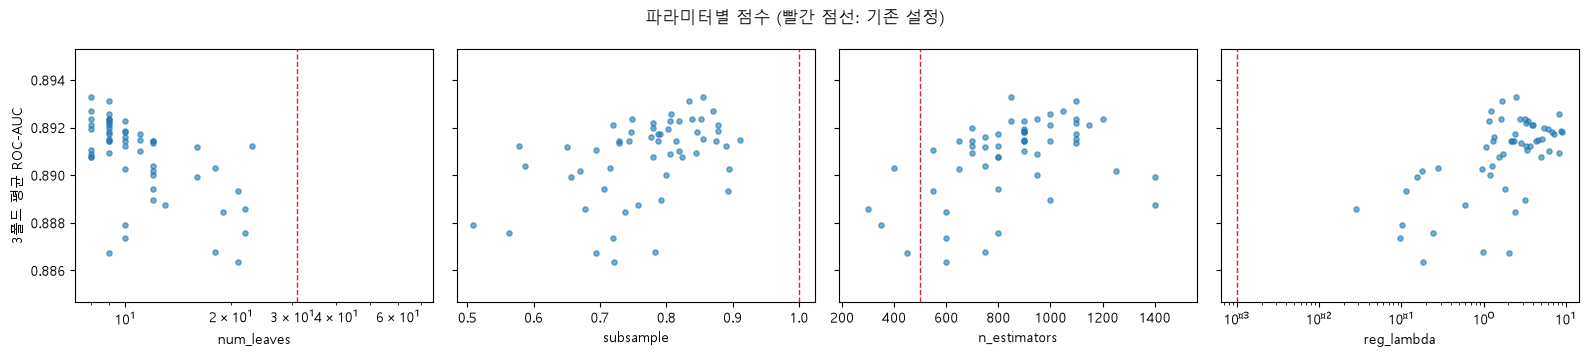

In [7]:
# 중요도 상위 파라미터가 점수와 어떤 관계인지 (상위 4개)
top = imp.sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(1, len(top), figsize=(4 * len(top), 3.6), sharey=True)
for ax, p in zip(axes, top):
    ax.scatter(trials[p], trials["roc_auc_mean"], s=14, alpha=0.6)
    ax.axvline(trials.loc[0, p], color="C3", ls="--", lw=1)
    if p in ("learning_rate", "min_child_samples", "reg_lambda", "num_leaves"):
        ax.set_xscale("log")
    ax.set_xlabel(p)
axes[0].set_ylabel("3폴드 평균 ROC-AUC")
axes[0].set_ylim(trials["roc_auc_mean"].quantile(0.1) - 0.002, trials["roc_auc_mean"].max() + 0.002)
fig.suptitle("파라미터별 점수 (빨간 점선: 기존 설정)")
plt.tight_layout()

## 5. 채택 여부 판정 (3장 기준 적용)

In [8]:
best_params = {**study.best_params, "subsample_freq": 1}
best_cv = cv_scores(best_params)   # 다시 학습해 같은 점수가 나오는지도 확인

judge = pd.DataFrame({
    "기존 ROC-AUC": base_cv["roc_auc"].iloc[:3],
    "튜닝 ROC-AUC": best_cv["roc_auc"],
    "기존 PR-AUC": base_cv["pr_auc"].iloc[:3],
    "튜닝 PR-AUC": best_cv["pr_auc"],
})
judge["ROC-AUC 차이"] = judge["튜닝 ROC-AUC"] - judge["기존 ROC-AUC"]
judge.loc["평균"] = judge.mean()

gain = judge.loc["평균", "ROC-AUC 차이"]
all_folds = bool((judge["ROC-AUC 차이"].iloc[:3] > 0).all())
ADOPT = gain >= 0.003 and all_folds
print(f"조건 1 평균 +0.003 이상: {gain:+.4f} → {'통과' if gain >= 0.003 else '미달'}")
print(f"조건 2 3개 폴드 모두 개선: {'통과' if all_folds else '미달'}")
print("판정:", "튜닝 설정 채택" if ADOPT else "기존 설정 유지")
print("튜닝 설정:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in best_params.items()})
judge.round(4)

조건 1 평균 +0.003 이상: +0.0161 → 통과
조건 2 3개 폴드 모두 개선: 미달
판정: 기존 설정 유지
튜닝 설정: {'learning_rate': 0.0149, 'n_estimators': 850, 'num_leaves': 8, 'min_child_samples': 80, 'subsample': 0.856, 'colsample_bytree': 0.8284, 'reg_lambda': 2.4503, 'subsample_freq': 1}


,기존 ROC-AUC,튜닝 ROC-AUC,기존 PR-AUC,튜닝 PR-AUC,ROC-AUC 차이
폴드 1,0.8724,0.8901,0.8297,0.8501,0.0177
폴드 2,0.8580,0.8894,0.8219,0.8573,0.0314
폴드 3,0.9011,0.9003,0.8564,0.8536,-0.0007
평균,0.8771,0.8933,0.8360,0.8536,0.0161


## 6. 테스트 기간 평가 (1회)

판정과 별개로, 튜닝이 미래 기간에서도 효과가 있었는지 확인하기 위해 둘 다 테스트한다.
- 학습: 테스트 이전 전체(2015-07 ~ 2017-04) — 2일차 최종 평가와 같은 조건
- **테스트 점수를 보고 판정을 바꾸지 않는다.** 판정은 5장에서 이미 끝났다.

In [9]:
test_models, test_rows = {}, {}
for name, params in {"LightGBM 기존 설정": BASE_PARAMS, "LightGBM 튜닝 설정": best_params}.items():
    t = time.perf_counter()
    test_models[name] = make_model(X, lgbm(**params), tree=True).fit(X.loc[dev_idx], y.loc[dev_idx])
    test_rows[name] = {**evaluate(test_models[name], X.loc[test_idx], y.loc[test_idx]),
                       "학습시간_초": round(time.perf_counter() - t, 1)}
compare(test_rows)

,roc_auc,pr_auc,accuracy,precision,recall,f1,학습시간_초
LightGBM 기존 설정,0.8704,0.8278,0.7758,0.8066,0.5880,0.6802,3.0
LightGBM 튜닝 설정,0.8651,0.8202,0.7706,0.7987,0.5805,0.6723,3.4


In [10]:
# 월별로도 비교 (2일차: 학습 시점에서 멀어질수록 성능이 떨어졌다)
by_month = {}
for m, idx in X.loc[test_idx].groupby(arrival.loc[test_idx].dt.to_period("M")).groups.items():
    row = {"예약수": len(idx), "취소율": y.loc[idx].mean()}
    for name, model in test_models.items():
        row[name] = evaluate(model, X.loc[idx], y.loc[idx])["roc_auc"]
    by_month[str(m)] = row
by_month = pd.DataFrame(by_month).T.astype(float)
by_month["차이"] = by_month["LightGBM 튜닝 설정"] - by_month["LightGBM 기존 설정"]
by_month.round(3)

,예약수,취소율,LightGBM 기존 설정,LightGBM 튜닝 설정,차이
2017-05,6313.0,0.438,0.908,0.907,-0.001
2017-06,5647.0,0.432,0.882,0.879,-0.003
2017-07,5313.0,0.373,0.835,0.828,-0.007
2017-08,4925.0,0.369,0.833,0.820,-0.013


## 7. 정리

**판정: 기존 설정 유지** (`num_leaves=31`, `n_estimators=500`, `learning_rate=0.05`)

| | 기존 설정 | 튜닝 설정 | 차이 |
|---|---|---|---|
| 폴드 1 (2016-05~08) | 0.872 | 0.890 | **+0.018** |
| 폴드 2 (2016-09~12) | 0.858 | 0.889 | **+0.031** |
| 폴드 3 (2017-01~04) | 0.901 | 0.900 | −0.001 |
| 3폴드 평균 | 0.877 | 0.893 | +0.016 |
| **테스트 (2017-05~08)** | **0.870** | 0.865 | −0.005 |

- 평균은 +0.016으로 조건 1을 넘었지만, **폴드 3에서 개선이 없어** 조건 2에서 탈락했다.
- 튜닝이 찾은 설정은 **아주 단순한 트리**다 (`num_leaves` 8~10, `min_child_samples` 50~90, 작은 학습률 + 많은 트리).
  점수를 좌우한 파라미터도 `num_leaves` 하나가 약 70%를 차지한다.

**왜 평균은 좋아졌는데 채택하지 않았나 — 학습 데이터 양에 따라 최적 복잡도가 다르다**
- 이득은 학습 기간이 짧은 폴드 1(10개월, 3.8만 건)·폴드 2(14개월, 5.9만 건)에 몰려 있다.
  데이터가 적을 때는 단순한 트리가 덜 외워서 유리하다.
- 학습 데이터가 7.9만 건인 폴드 3에서는 이득이 사라진다.
- 실제 운영과 테스트는 이보다 더 많은 데이터(9.7만 건)로 학습한다 → **운영 조건과 가장 닮은 폴드는 폴드 3**이고, 거기서 이득이 없었다.
- 폴드 평균은 세 폴드를 똑같이 취급하므로, 데이터가 적은 초기 폴드가 선호하는 설정으로 끌려갔다.

**테스트로 사후 확인 — 판정이 맞았다**
- 튜닝 설정은 테스트에서 0.005 낮고, 학습 시점에서 멀어질수록 차이가 커진다 (5월 −0.001 → 8월 −0.013).
- 평균만 보고 채택했다면 테스트 성능을 잃었을 것이다. **탐색 전에 정한 "모든 폴드에서 개선" 조건이 이를 막았다.**
- 테스트 점수는 판정에 쓰지 않았다. 판정은 5장에서 테스트를 보기 전에 끝났다.

**결론**
- 2일차의 대표값 비교(`num_leaves` 31 / 63 / 127)로 이미 충분했다. 체계적으로 튜닝해도 운영 조건에서는 더 얻을 것이 없었다.
- 2일차 결론 **"이 데이터에서는 알고리즘·하이퍼파라미터보다 피처와 평가 방식이 성능을 좌우한다"**가 튜닝으로도 다시 확인됐다.

**한계**
- LightGBM만 튜닝했다 (XGBoost·CatBoost는 2일차에 동률이라 제외).
- 시드 하나로 실행했다. 폴드 3의 −0.001은 시드에 따른 흔들림 범위 안일 수 있다 — 그래도 "개선이 없다"는 결론은 같다.
- 다시 한다면: 폴드별 가중치(최근 폴드를 더 크게)나 학습 창 길이를 고정한 폴드로, 운영 조건에 더 가까운 목적 함수를 쓴다.
